# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170341        # <-- your full roll number
NAME = "Ashish"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170341   Name: Ashish   Fingerprint: D55EA071   Tickets: 13

Ticket_ID                                                                                         Ticket_Text
      T01                                               The VPN is running slowly. Is there another solution?
      T02                                              The projector has stopped syncing. Can you check this?
      T03                                        Student portal stopped responding on my laptop. Please help.
      T04                                                                         Ticket #4521 is still open.
      T05                                                               I need Windows 11 by 5.30 p.m. today.
      T06               I tried restarting the lms after restarting the system. It works on another computer.
      T07                                                               I tried again... still no response!!!
      T08                               I 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
results, rows = {}, []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    results[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })
q1 = pd.DataFrame(rows)
total_row = {"Ticket_ID": "TOTAL", **{c: int(q1[c].sum()) for c in q1.columns if c != "Ticket_ID"}}
q1_table = pd.concat([q1, pd.DataFrame([total_row])], ignore_index=True)
display(q1_table)


SEL = FOCUS[0]
r = results[SEL]
print(f"\nSelected ticket {SEL}: {df.loc[df.Ticket_ID == SEL, 'Ticket_Text'].iloc[0]!r}")
print("Sentences   :", r["sentences"])
print("Tokens      :", r["tokens"])
print("Punctuation :", r["punct"])
print("Stopwords   :", r["stops"])
print("Final tokens:", r["final"])

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,11,2,4,10,5
1,T02,2,11,2,5,11,4
2,T03,2,11,2,2,10,7
3,T04,1,7,2,1,7,4
4,T05,1,9,1,2,9,6
5,T06,2,16,2,6,13,8
6,T07,2,10,4,3,8,3
7,T08,2,16,2,7,16,7
8,T09,2,13,2,5,11,6
9,T10,2,19,2,8,19,9



Selected ticket T01: 'The VPN is running slowly. Is there another solution?'
Sentences   : ['The VPN is running slowly.', 'Is there another solution?']
Tokens      : ['the', 'vpn', 'is', 'running', 'slowly', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation : ['.', '?']
Stopwords   : ['the', 'is', 'is', 'there']
Final tokens: ['vpn', 'running', 'slowly', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

ca, n't  from can't, doesn't , Wi, Fi  from Wi-Fi p.m.  from p.m. 4521  from #4521 lms, vpn  from LMS, VPN.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

PATTERNS = {
    "words_longer_than_5": r"\b[A-Za-z]{6,}\b",
    "numbers": r"(?<![A-Za-z0-9])(?:0x[0-9A-Fa-f]+|\d+(?:[.,]\d+)*(?:-\d+)*)",
    "capitalized_words": r"\b[A-Z][A-Za-z]*\b",
    "words_starting_with_vowel": r"\b[aeiouAEIOU][A-Za-z]*\b",
}

EMAIL_RE = r"(?i)\b[A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?(?:\.[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?)+\b"
URL_RE = r"(?i)\b(?:https?://|www\.)[^\s<>]+"

PHONE_RE = r"(?<!\w)(?:\+\d{1,3}[ -]?)?(?:\d{3,5}[ -]){1,2}\d{4,5}(?!\w)"

def extract_regex_results(text):
    return {name: re.findall(pattern, text) for name, pattern in PATTERNS.items()}

print("REGEX EXTRACTIONS FROM RAW TICKETS")
for row in df.itertuples(index=False):
    print(f"\n{row.Ticket_ID}: {row.Ticket_Text}")
    for name, matches in extract_regex_results(row.Ticket_Text).items():
        print(f"  {name}: {matches}")

print("\nREGEX EXTRACTIONS FROM TEST_LINES")
for line in TEST_LINES:
    print("\nOriginal:", line)
    for name, matches in extract_regex_results(line).items():
        print(f"  {name}: {matches}")
    cleaned = re.sub(URL_RE, "<URL>", line)
    cleaned = re.sub(EMAIL_RE, "<EMAIL>", cleaned)
    cleaned = re.sub(PHONE_RE, "<PHONE>", cleaned)
    print("  Replaced:", cleaned)






REGEX EXTRACTIONS FROM RAW TICKETS

T01: The VPN is running slowly. Is there another solution?
  words_longer_than_5: ['running', 'slowly', 'another', 'solution']
  numbers: []
  capitalized_words: ['The', 'VPN', 'Is']
  words_starting_with_vowel: ['is', 'Is', 'another']

T02: The projector has stopped syncing. Can you check this?
  words_longer_than_5: ['projector', 'stopped', 'syncing']
  numbers: []
  capitalized_words: ['The', 'Can']
  words_starting_with_vowel: []

T03: Student portal stopped responding on my laptop. Please help.
  words_longer_than_5: ['Student', 'portal', 'stopped', 'responding', 'laptop', 'Please']
  numbers: []
  capitalized_words: ['Student', 'Please']
  words_starting_with_vowel: ['on']

T04: Ticket #4521 is still open.
  words_longer_than_5: ['Ticket']
  numbers: ['4521']
  capitalized_words: ['Ticket']
  words_starting_with_vowel: ['is', 'open']

T05: I need Windows 11 by 5.30 p.m. today.
  words_longer_than_5: ['Windows']
  numbers: ['11', '5.30']
  capit

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 16

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
from nltk.tokenize import RegexpTokenizer


TOKEN_PATTERN = r"(?i:https?://[^\s<>]+|www\.[^\s<>]+)|(?i:[A-Z0-9.!#$%&'*+/=?^_`{|}~-]+@[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?(?:\.[A-Z0-9](?:[A-Z0-9-]*[A-Z0-9])?)+)|(?:\+\d{1,3}[ -]?)?(?:\d{3,5}[ -]){1,2}\d{4,5}|\b\d+(?:\.\d+)+\b|\b\d+\.\d+\b|\b[A-Za-z]+(?:['’][A-Za-z]+)+\b|\b[A-Za-z]+(?:-[A-Za-z]+)+\b|\b[A-Za-z]+\b|\d+|[^\w\s]"
my_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):

    return my_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print("\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\nCUSTOM TOKENIZER ON GENERATED TICKETS")
comparison_rows = []
for row in df.itertuples(index=False):
    custom = my_tokenize(row.Ticket_Text)
    standard = word_tokenize(row.Ticket_Text)
    comparison_rows.append({
        "Ticket_ID": row.Ticket_ID,
        "Custom token count": len(custom),
        "word_tokenize count": len(standard),
        "Different token lists?": custom != standard,
        "Custom tokens": custom,
        "word_tokenize tokens": standard,
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)
different_tickets = comparison_df[comparison_df["Different token lists?"]]
print(f"\nTickets with different tokenization: {len(different_tickets)} out of {len(df)}")


CUSTOM TOKENIZER ON TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in a

,Ticket_ID,Custom token count,word_tokenize count,Different token lists?,Custom tokens,word_tokenize tokens
0,T01,11,11,False,"[The, VPN, is, running, slowly, ., Is, there, ...","[The, VPN, is, running, slowly, ., Is, there, ..."
1,T02,11,11,False,"[The, projector, has, stopped, syncing, ., Can...","[The, projector, has, stopped, syncing, ., Can..."
2,T03,11,11,False,"[Student, portal, stopped, responding, on, my,...","[Student, portal, stopped, responding, on, my,..."
3,T04,7,7,False,"[Ticket, #, 4521, is, still, open, .]","[Ticket, #, 4521, is, still, open, .]"
4,T05,12,9,True,"[I, need, Windows, 11, by, 5.30, p, ., m, ., t...","[I, need, Windows, 11, by, 5.30, p.m., today, .]"
5,T06,16,16,False,"[I, tried, restarting, the, lms, after, restar...","[I, tried, restarting, the, lms, after, restar..."
6,T07,12,10,True,"[I, tried, again, ., ., ., still, no, response...","[I, tried, again, ..., still, no, response, !,..."
7,T08,15,16,True,"[I, can't, open, the, VPN, after, resetting, m...","[I, ca, n't, open, the, VPN, after, resetting,..."
8,T09,13,13,False,"[LMS, is, running, slowly, after, resetting, m...","[LMS, is, running, slowly, after, resetting, m..."
9,T10,19,19,False,"[I, keep, getting, logged, out, of, the, print...","[I, keep, getting, logged, out, of, the, print..."



Tickets with different tokenization: 4 out of 13


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*4


---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd

unique_final_tokens = sorted({token for result in results.values() for token in result["final"]})
porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(r"ing$", min=4)
lemmatizer = WordNetLemmatizer()

def penn_to_wordnet(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

tags = dict(pos_tag(unique_final_tokens))
rows = []
for word in unique_final_tokens:
    pos = penn_to_wordnet(tags[word])
    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp (-ing)": regexp_stemmer.stem(word),
        "POS tag": tags[word],
        "WordNet lemma": lemmatizer.lemmatize(word, pos=pos),
    }
    if len({outputs[k] for k in ["Porter", "Lancaster", "Regexp (-ing)", "WordNet lemma"]}) > 1:
        rows.append(outputs)

stem_diff_df = pd.DataFrame(rows, columns=["Word", "Porter", "Lancaster", "Regexp (-ing)", "POS tag", "WordNet lemma"])
print(f"Unique final tokens: {len(unique_final_tokens)}")
print("RegexpStemmer rule: remove a final 'ing' from words of at least 4 characters.")
print("Examples from this dataset that motivate the rule:", [w for w in unique_final_tokens if w.endswith("ing")][:12])
print("Only rows with differing outputs are shown:")
display(stem_diff_df)

Unique final tokens: 49
RegexpStemmer rule: remove a final 'ing' from words of at least 4 characters.
Examples from this dataset that motivate the rule: ['disconnecting', 'getting', 'resetting', 'responding', 'restarting', 'running', 'syncing']
Only rows with differing outputs are shown:


,Word,Porter,Lancaster,Regexp (-ing),POS tag,WordNet lemma
0,another,anoth,anoth,another,DT,another
1,campus,campu,camp,campus,VB,campus
2,computer,comput,comput,computer,NN,computer
3,connected,connect,connect,connected,VBN,connect
4,failed,fail,fail,failed,VBD,fail
5,getting,get,get,gett,VBG,get
6,keeps,keep,keep,keeps,NNS,keep
7,lms,lm,lms,lms,NNS,lm
8,logged,log,log,logged,VBD,log
9,need,need,nee,need,VB,need


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

overstem -> another to anoth, under -> running to runn


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

--- Corpus Statistics ---


,Corpus,Tokens,Unique Types,TTR
0,S1 (All),158,77,0.4873
1,S2 (No Punctuation),131,71,0.5420
2,S3 (Final),75,49,0.6533
3,S4 (S3 + Porter),75,48,0.6400



--- Top 10 Words in S1 ---
  .: 17
  the: 12
  is: 6
  i: 5
  ?: 4
  vpn: 3
  another: 3
  this: 3
  student: 3
  portal: 3

--- Top 10 Words in S3 ---
  vpn: 3
  another: 3
  student: 3
  portal: 3
  open: 3
  running: 2
  slowly: 2
  solution: 2
  stopped: 2
  check: 2

--- Top 5 Bigrams in S1 ---
  . i: 4
  . the: 4
  the vpn: 3
  student portal: 3
  is running: 2

--- Top 5 Bigrams in S3 ---
  student portal: 3
  running slowly: 2
  another solution: 2
  resetting password: 2
  problem occurs: 2


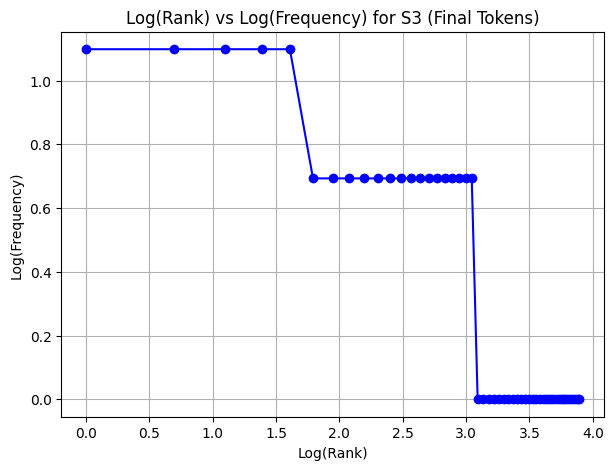

In [16]:
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams


s1_tokens = []
for r in results.values():
    s1_tokens.extend(r["tokens"])


s2_tokens = [t for t in s1_tokens if not is_punct(t)]


s3_tokens = []
for r in results.values():
    s3_tokens.extend(r["final"])

s4_tokens = [porter.stem(t) for t in s3_tokens]


def compute_stats(name, tokens):
    num_tokens = len(tokens)
    num_types = len(set(tokens))
    ttr = num_types / num_tokens if num_tokens > 0 else 0
    return {"Corpus": name, "Tokens": num_tokens, "Unique Types": num_types, "TTR": round(ttr, 4)}


stats_rows = [
    compute_stats("S1 (All)", s1_tokens),
    compute_stats("S2 (No Punctuation)", s2_tokens),
    compute_stats("S3 (Final)", s3_tokens),
    compute_stats("S4 (S3 + Porter)", s4_tokens)
]
stats_df = pd.DataFrame(stats_rows)
print("--- Corpus Statistics ---")
display(stats_df)


s1_counts = Counter(s1_tokens)
s3_counts = Counter(s3_tokens)

print("\n--- Top 10 Words in S1 ---")
for word, count in s1_counts.most_common(10):
    print(f"  {word}: {count}")

print("\n--- Top 10 Words in S3 ---")
for word, count in s3_counts.most_common(10):
    print(f"  {word}: {count}")


s1_bigrams = Counter(bigrams(s1_tokens))
s3_bigrams = Counter(bigrams(s3_tokens))

print("\n--- Top 5 Bigrams in S1 ---")
for bg, count in s1_bigrams.most_common(5):
    print(f"  {' '.join(bg)}: {count}")

print("\n--- Top 5 Bigrams in S3 ---")
for bg, count in s3_bigrams.most_common(5):
    print(f"  {' '.join(bg)}: {count}")


ranks = range(1, len(s3_counts) + 1)
frequencies = [count for _, count in s3_counts.most_common()]
log_ranks = [math.log(r) for r in ranks]
log_freqs = [math.log(f) for f in frequencies]

plt.figure(figsize=(7, 5))
plt.plot(log_ranks, log_freqs, marker='o', linestyle='-', color='b')
plt.title("Log(Rank) vs Log(Frequency) for S3 (Final Tokens)")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* because of removing puntiation stopwords and stemming
